## Embeding Vactor

- Embedding models transform raw text—such as a sentence, paragraph, or tweet
- into a fixed-length vector of numbers that captures its semantic meaning.
- These vectors allow machines to compare and search text based on meaning rather than exact words.
- In practice, this means that texts with similar ideas are placed close together in the vector space.

For Example:
- Instead of matching only the phrase “machine learning”, 
- embeddings can surface documents that discuss related concepts even when different wording is used.

In [8]:
from dotenv import load_dotenv
load_dotenv()

True

In [9]:
documents = [
    "Machine learning is a subset of artificial intelligence",
    "Deep learning uses neural networks with multiple layers",
    "Python is a programming language popular for data science",
    "Current president of France is Emanual Macron",
    "AI models can understand and generate human language"
]

In [10]:
# Not enough credits 😒

from langchain_openai import OpenAIEmbeddings

# Embeding Model will be differet from llm models.
# embeddings = OpenAIEmbeddings(model="text-embedding-3-small")
# vector = embeding.embed_documents(documents)
# print(len(vector))

In [11]:
# Google
from langchain_google_genai import GoogleGenerativeAIEmbeddings

# Embeding Model will be differet from llm models.
embeddings = GoogleGenerativeAIEmbeddings(model="gemini-embedding-001")
vactor = embeddings.embed_documents("Hello World")
vactor

[[-0.016372832,
  0.013813561,
  0.013894072,
  -0.0782227,
  -0.016500361,
  0.013281048,
  0.016156241,
  0.006484267,
  0.0027471962,
  -0.0077986256,
  -0.009503913,
  -0.016797954,
  0.004657148,
  -0.0048378464,
  0.17070496,
  -0.0029155298,
  0.009090932,
  0.011881032,
  0.00011048462,
  -0.0018181393,
  0.006870429,
  -0.0029864602,
  0.015406045,
  -0.021015288,
  0.019104788,
  -0.021567952,
  0.0055746743,
  0.017206125,
  0.030846562,
  -0.00022085459,
  -0.0047296276,
  0.015639424,
  0.0024307945,
  0.01653014,
  0.021424696,
  0.018148843,
  0.017227367,
  -0.0126292035,
  0.01957177,
  0.023071324,
  0.009647776,
  0.003146558,
  0.0032347487,
  -0.012575404,
  -0.00023258911,
  0.011938705,
  -0.003232339,
  -0.012547341,
  0.0036637946,
  0.024993334,
  0.00066301675,
  0.0033077027,
  -0.01866358,
  -0.26272243,
  -0.008697337,
  0.0048631146,
  -0.007320559,
  0.017455146,
  0.006119266,
  -0.016306447,
  -0.006843881,
  0.012445126,
  0.0013659864,
  -0.023019735

In [12]:
# Google
from langchain_google_genai import GoogleGenerativeAIEmbeddings

# Embeding Model will be differet from llm models.
embeddings = GoogleGenerativeAIEmbeddings(model="gemini-embedding-001")
vactor = embeddings.embed_documents(documents)

print(len(vactor))

# length of first text data vactors
print(len(vactor[0]))


5
3072


### Vactor Store (Data Base)

- A vector stores embedded data and performs similarity search.
- Instead of matching only the phrase “machine learning”, 
- embeddings can surface documents that discuss related concepts even when different wording is used.

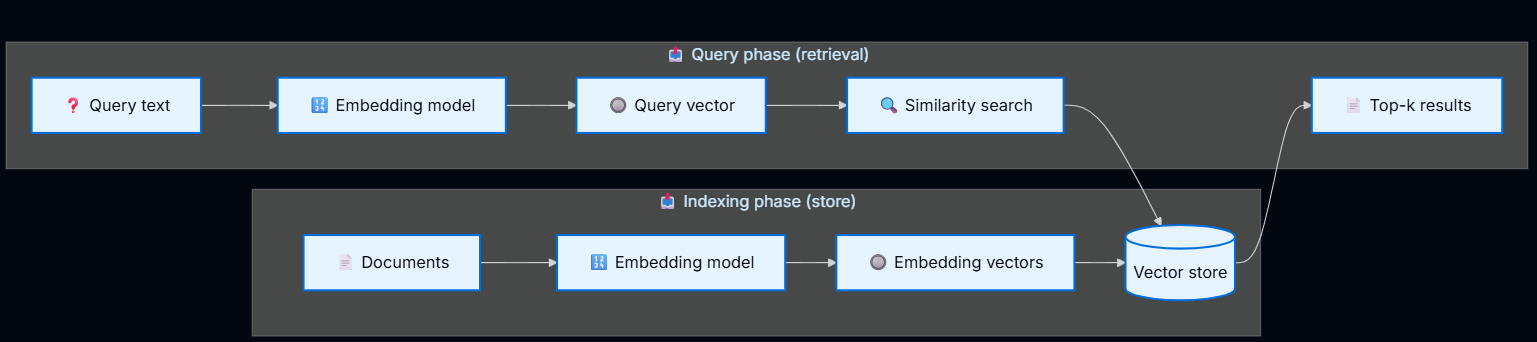


- Currently we are at `📥 Indexing phase (store)`
- In next lesson:
    - 📤 Query phase (retrieval)

In [13]:
# we have installed & used the Chorama DB
from langchain_chroma import Chroma

# we are using this for text
vectore_store = Chroma.from_texts(
    texts=documents,
    embedding=embeddings,
    persist_directory="./vector_db" # for permanemt store, reuseability  
)

### Similarty Search
- Similarity search is the process of finding items that are similar to a given query item based on their vector representations.

In [18]:
query = "Coding"
res = vectore_store.similarity_search(query=query, k=2) # k represent the max number of result we want
res

[Document(id='f806e6de-11b0-4cff-b6ec-8558d6eb68ef', metadata={}, page_content='Python is a programming language popular for data science'),
 Document(id='6bbe5b99-ba2f-4cfe-99c3-c28cfa05d52b', metadata={}, page_content='Deep learning uses neural networks with multiple layers')]